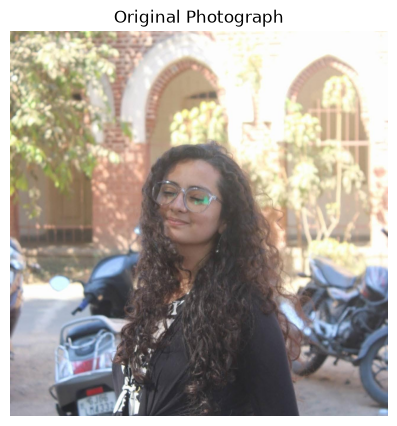

Image loaded: (1304, 1279, 3)


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the original photograph
image_path = Path("../data/images/original.jpeg")
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path.resolve()}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display the image
plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
plt.title("Original Photograph")
plt.axis("off")
plt.show()

print("Image loaded:", image.shape)


Extract HOG features

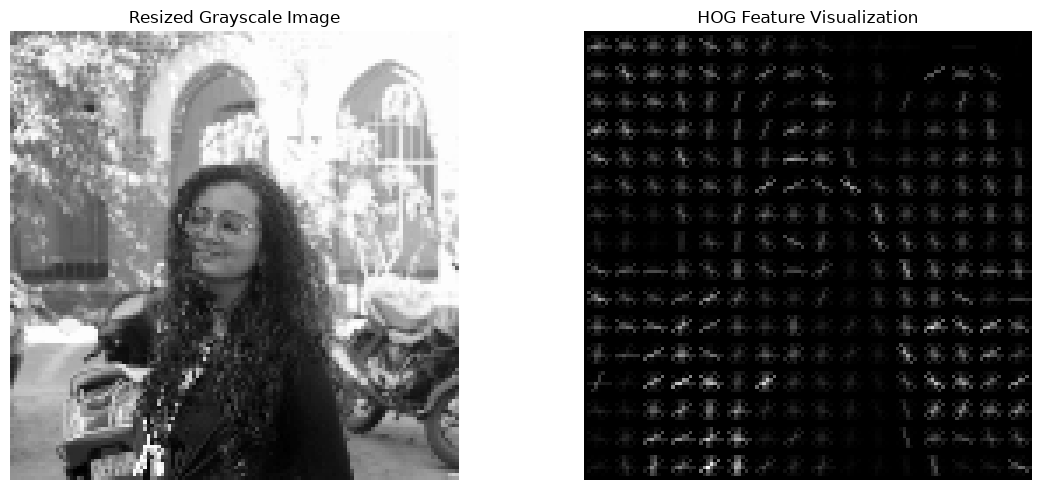

HOG feature extraction completed.
HOG feature vector length: 8100


In [3]:
from skimage.feature import hog

# Resize the image to a standard size for HOG
hog_image = cv2.resize(gray, (128, 128))

# Extract HOG features and generate a visualization
hog_features, hog_visualization = hog(
    hog_image,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

# Display the image and HOG visualization
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(hog_image, cmap="gray")
plt.title("Resized Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_visualization, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

print("HOG feature extraction completed.")
print("HOG feature vector length:", len(hog_features))


In [4]:
output_dir = Path("../outputs/features")
output_dir.mkdir(parents=True, exist_ok=True)

hog_visualization_uint8 = cv2.normalize(
    hog_visualization,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

cv2.imwrite(
    str(output_dir / "hog_visualization.png"),
    hog_visualization_uint8
)

np.save(output_dir / "hog_features.npy", hog_features)

print("HOG visualization and feature vector saved.")


HOG visualization and feature vector saved.


Detect SIFT keypoints

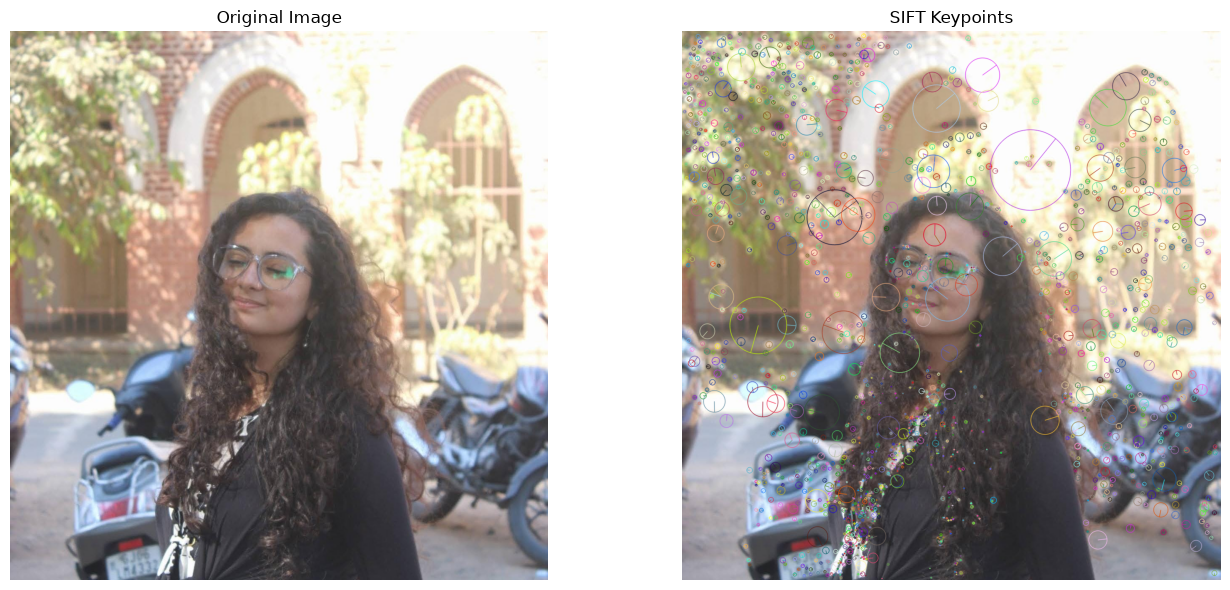

SIFT feature extraction completed.
Number of keypoints: 1978
Descriptor shape: (1978, 128)


In [5]:
# Experiment 2: SIFT Feature Extraction

# Create the SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(gray, None)

# Draw keypoints on the original image
sift_visualization = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display the results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sift_visualization, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints")
plt.axis("off")

plt.tight_layout()
plt.show()

print("SIFT feature extraction completed.")
print("Number of keypoints:", len(keypoints))
print("Descriptor shape:", descriptors.shape if descriptors is not None else None)


In [6]:
# Save SIFT visualization and descriptors

output_dir = Path("../outputs/features")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "sift_keypoints.png"),
    sift_visualization
)

if descriptors is not None:
    np.save(output_dir / "sift_descriptors.npy", descriptors)

print("SIFT outputs saved successfully.")


SIFT outputs saved successfully.


Image Rotation & resizing

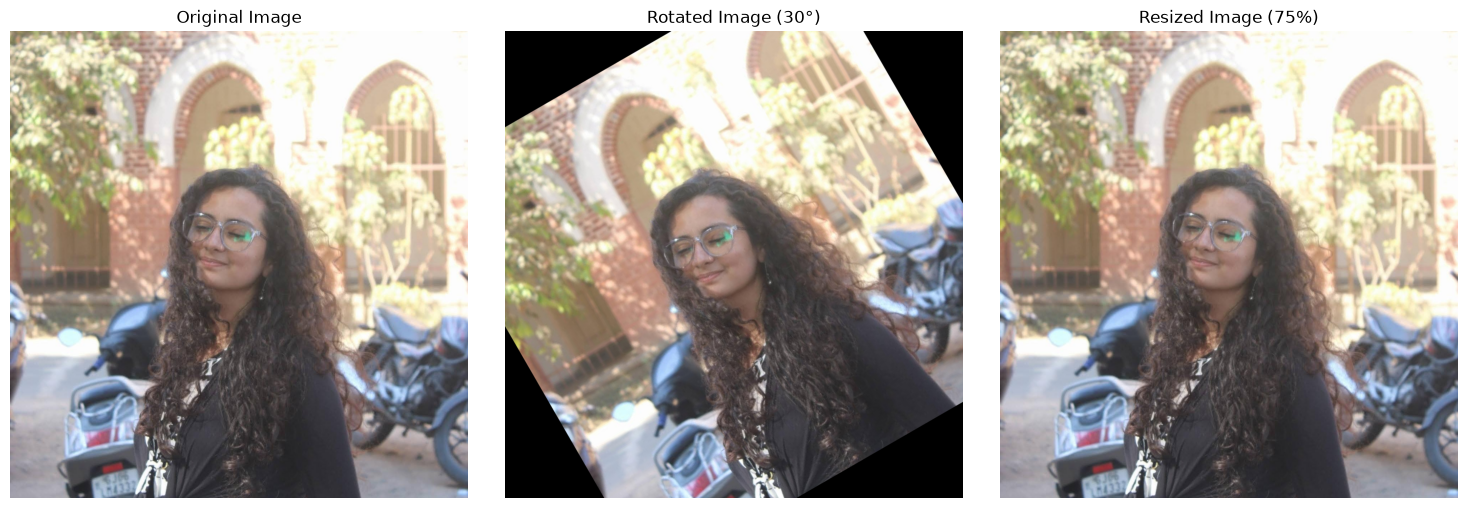

In [7]:
# Experiment 3: Image Rotation and Resizing

height, width = image.shape[:2]
center = (width // 2, height // 2)

# Rotate the image by 30 degrees
rotation_matrix = cv2.getRotationMatrix2D(center, 30, 1.0)
rotated_image = cv2.warpAffine(
    image,
    rotation_matrix,
    (width, height)
)

# Resize the image to 75% of its original dimensions
resized_image = cv2.resize(
    image,
    None,
    fx=0.75,
    fy=0.75,
    interpolation=cv2.INTER_LINEAR
)

# Convert transformed images to grayscale
rotated_gray = cv2.cvtColor(rotated_image, cv2.COLOR_BGR2GRAY)
resized_gray = cv2.cvtColor(resized_image, cv2.COLOR_BGR2GRAY)

# Display all three images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

display_images = [
    (image, "Original Image"),
    (rotated_image, "Rotated Image (30°)"),
    (resized_image, "Resized Image (75%)")
]

for ax, (img, title) in zip(axes, display_images):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


Match SIFT features

In [8]:
# Detect SIFT features in transformed images
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_gray, None
)

resized_keypoints, resized_descriptors = sift.detectAndCompute(
    resized_gray, None
)

# Create the descriptor matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

def get_good_matches(descriptors1, descriptors2):
    if descriptors1 is None or descriptors2 is None:
        return []

    if len(descriptors1) < 2 or len(descriptors2) < 2:
        return []

    pairs = bf.knnMatch(descriptors1, descriptors2, k=2)

    good_matches = []
    for pair in pairs:
        if len(pair) == 2:
            first, second = pair
            if first.distance < 0.75 * second.distance:
                good_matches.append(first)

    return good_matches

# Match original features with transformed image features
rotation_matches = get_good_matches(
    descriptors, rotated_descriptors
)

resize_matches = get_good_matches(
    descriptors, resized_descriptors
)

print("Original SIFT keypoints:", len(keypoints))
print("Rotated SIFT keypoints:", len(rotated_keypoints))
print("Good matches after rotation:", len(rotation_matches))
print("Resized SIFT keypoints:", len(resized_keypoints))
print("Good matches after resizing:", len(resize_matches))


Original SIFT keypoints: 1978
Rotated SIFT keypoints: 1608
Good matches after rotation: 1214
Resized SIFT keypoints: 1686
Good matches after resizing: 1406


Visualise and save

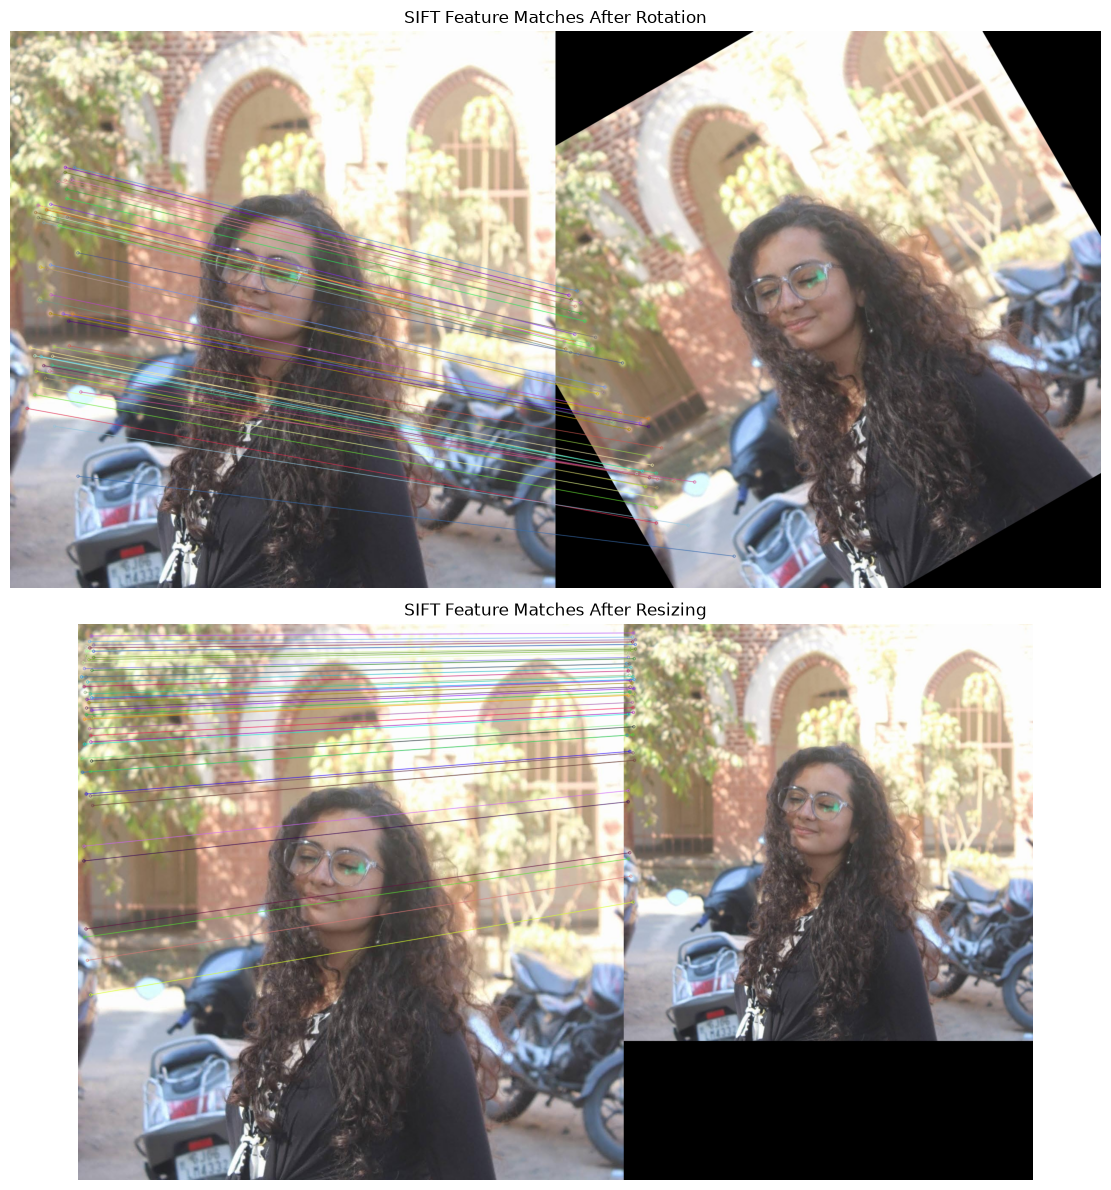

Transformed images and feature-match visualizations saved.


In [9]:
# Draw feature matches
rotation_match_image = cv2.drawMatches(
    image, keypoints,
    rotated_image, rotated_keypoints,
    rotation_matches[:50], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

resize_match_image = cv2.drawMatches(
    image, keypoints,
    resized_image, resized_keypoints,
    resize_matches[:50], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display results
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

axes[0].imshow(cv2.cvtColor(rotation_match_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("SIFT Feature Matches After Rotation")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(resize_match_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("SIFT Feature Matches After Resizing")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Save results
output_dir = Path("../outputs/features")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "rotated_image.png"), rotated_image
)
cv2.imwrite(
    str(output_dir / "resized_image.png"), resized_image
)
cv2.imwrite(
    str(output_dir / "sift_rotation_matches.png"), rotation_match_image
)
cv2.imwrite(
    str(output_dir / "sift_resize_matches.png"), resize_match_image
)

print("Transformed images and feature-match visualizations saved.")
